In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 

dataset = pd.read_csv('/home/siyam/Desktop/Dataset/Part 3 - Classification/Data/Social_Network_Ads.csv')
x = dataset.iloc[:, 2:-1].values
y = dataset.iloc[:, -1].values

from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.25, random_state=1)

# print(x_train)
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
x_train = sc.fit_transform(x_train)
x_test = sc.transform(x_test)

# print(x_train)

from sklearn.linear_model import LogisticRegression
model = LogisticRegression(random_state=0)
model.fit(x_train, y_train)
y_pred = model.predict(x_test)

# cnt = 0
# for i in range(len(y_pred)):
#     if y_test[i] != y_pred[i]:
#         cnt += 1 
#     print(y_test[i], y_pred[i])

# print("mismatched element = ", cnt)

# print(model.predict([[20,123]]))

from sklearn.metrics import confusion_matrix, accuracy_score
mat = confusion_matrix(y_test, y_pred)
print(mat)
accuracy_score(y_test, y_pred)

[[52  6]
 [11 31]]


0.83

# Visualizing The Data

Training Set Visualization

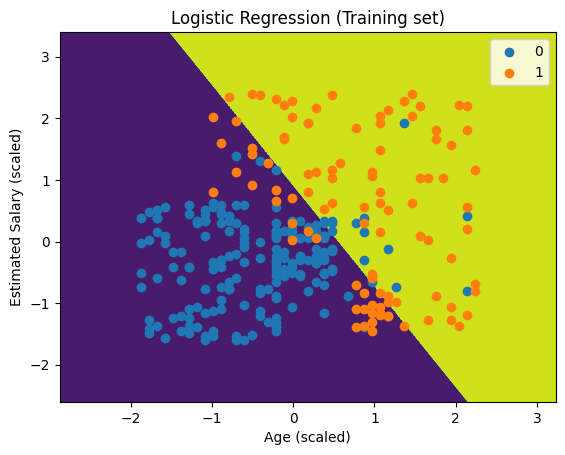

In [6]:
from matplotlib.colors import ListedColormap

X_set, y_set = x_train, y_train

X1, X2 = np.meshgrid(
    np.arange(X_set[:,0].min()-1, X_set[:,0].max()+1, 0.01),
    np.arange(X_set[:,1].min()-1, X_set[:,1].max()+1, 0.01)
)

# plt.contourf(X1, X2, prediction_map, alpha=0.75)
# print(np.array([X1.ravel(), X2.ravel()]).T)
plt.contourf(
    X1,
    X2,
    model.predict(np.array([X1.ravel(), X2.ravel()]).T).reshape(X1.shape))

for i, j in enumerate(np.unique(y_set)):
    plt.scatter(
        X_set[y_set == j, 0],
        X_set[y_set == j, 1],
        label=j
    )

plt.title('Logistic Regression (Training set)')
plt.xlabel('Age (scaled)')
plt.ylabel('Estimated Salary (scaled)')
plt.legend()
plt.show()